# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

## Preliminares

In [12]:
import pandas as pd

from src.modeling import (
    cargar_datos_clean, filtrar_pares_restantes, separar_train_test,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots, top_correlaciones_objetivo
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 931 entries, 2007-12-17 to 2026-11-02
Columns: 122 entries, EURUSD_intra_weekly to VIX_vel_50d_yeo
dtypes: float64(122)
memory usage: 894.6 KB


In [13]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

## Analisis de variables

In [14]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "skew"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
EURUSD_return_skew_lag1,931.0,-0.020223,0.138455,-0.359504,-0.113925,-0.023563,0.065156,0.416551
GBPUSD_return_skew_lag1,931.0,0.036402,0.147215,-0.302718,-0.077991,0.029893,0.158883,0.413965
USDJPY_return_skew_lag1,931.0,-0.084108,0.154033,-0.383369,-0.204081,-0.101142,0.013048,0.348251
USDCAD_return_skew_lag1,931.0,0.030506,0.127450,-0.263989,-0.064549,0.028562,0.128595,0.316744
USDCHF_return_skew_lag1,931.0,-0.036647,0.165654,-0.415181,-0.144612,-0.007808,0.094802,0.309857
AUDUSD_return_skew_lag1,931.0,-0.059487,0.100647,-0.313033,-0.128721,-0.063534,0.013331,0.195088
Gold_return_skew_lag1,931.0,-0.059630,0.174812,-0.472646,-0.170365,-0.073772,0.042650,0.409314
Oil_return_skew_lag1,931.0,-0.102039,0.121840,-0.541806,-0.174231,-0.098301,-0.018289,0.190037
SPY_return_skew_lag1,931.0,-0.098511,0.152391,-0.416515,-0.202758,-0.138811,0.018838,0.293454
EURUSD_gap_skew_lag1,931.0,-0.099374,0.288330,-0.671797,-0.348300,-0.065778,0.078302,0.768783


In [15]:
# Asimetrias general
mostrar_asimetrias(df_clean)

VIX_level                           2.382774
USDCAD_std_lag1_log                 1.730749
USDCHF_std_lag1_log                 1.103859
AUDUSD_gap_skew_lag1                1.019839
Oil_vol_directional_lag1_log        0.971718
STLFSI_vel_50d                      0.953561
EURUSD_open_gap_zscore_yeo          0.812118
GBPUSD_std_lag1_log                 0.794907
Real_yield_vel_50d                  0.787467
Oil_std_lag1_log                    0.726685
AUDUSD_vol_directional_lag1_log     0.572392
SPY_accel_diff_zscore_lag1          0.549106
AUDUSD_sma15_pct_diff_sma50_lag1    0.497620
SPY_return_skew_lag1                0.482809
GBPUSD_vol_directional_lag1_log     0.434020
USDJPY_return_skew_lag1             0.393584
USDJPY_sma15_pct_diff_sma50_lag1    0.378803
AUDUSD_accel_diff_zscore_lag1       0.369585
SPY_vol_directional_lag1_log        0.349884
Gold_return_skew_lag1               0.308688
GBPUSD_acceleration_zscore_lag1     0.282458
SPY_acceleration_zscore_lag1        0.268045
USDCHF_gap

In [16]:
# Asimetria por grupo
cadena = "_yield_spread_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

AUDUSD_yield_spread_zscore         0.217118
EURUSD_yield_spread_zscore_skew    0.118258
GBPUSD_yield_spread_zscore_skew    0.112428
USDCHF_yield_spread_zscore_skew    0.092586
USDJPY_yield_spread_zscore         0.081796
AUDUSD_yield_spread_zscore_skew    0.076337
EURUSD_yield_spread_zscore         0.059065
USDCAD_yield_spread_zscore_vel     0.039907
GBPUSD_yield_spread_zscore        -0.016033
USDJPY_yield_spread_zscore_skew   -0.018015
USDCAD_yield_spread_zscore        -0.116163
USDCHF_yield_spread_zscore        -0.212616
USDCAD_yield_spread_zscore_skew   -0.243343


Cont


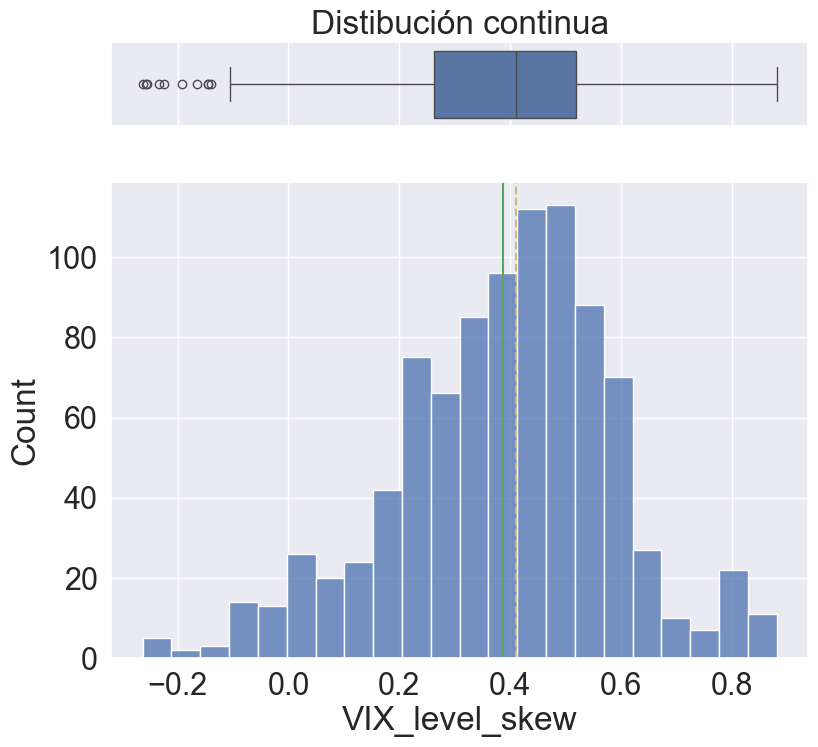

In [17]:
# Visualizar columna
col = 'VIX_level_skew'
pintar_columna(df_clean[col])

## Correlaciones

In [18]:
# Tabla de Correlaciones general
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
1114,AUDUSD_sma15_pct_diff_sma50_lag1,USDCAD_sma15_pct_diff_sma50_lag1,0.842330
792,USDCHF_sma15_pct_diff_sma50_lag1,EURUSD_sma15_pct_diff_sma50_lag1,0.781493
4274,USDCHF_std_lag1_log,EURUSD_std_lag1_log,0.764824
567,USDCHF_acceleration_zscore_lag1,EURUSD_acceleration_zscore_lag1,0.747901
752,USDCHF_range10_position_lag1,EURUSD_range10_position_lag1,0.742171
5197,AUDUSD_vol_directional_lag1_log,AUDUSD_range10_position_lag1,0.722361
4667,EURUSD_vol_directional_lag1_log,EURUSD_range10_position_lag1,0.721989
4366,AUDUSD_std_lag1_log,EURUSD_std_lag1_log,0.720015
675,USDCHF_accel_diff_zscore_lag1,EURUSD_accel_diff_zscore_lag1,0.713817
4771,GBPUSD_vol_directional_lag1_log,GBPUSD_range10_position_lag1,0.713241


* `vol_directional` y `range_position`: la precision del modelo disminuye al quitar la variable menos significativa de ellas. Por lo tanto se mantienen ambas variables a pesar de su alta correlacion.

In [19]:
# Correlaciones con la variable objetivo continua
simbolo_objetivo = 'EURUSD'
objetivo = f"{simbolo_objetivo}_intra_weekly"

top_correlaciones_objetivo(df=df_clean, target_col=objetivo)

,Variable,Correlación
0,GBPUSD_intra_weekly,0.643587
1,USDCHF_intra_weekly,-0.639030
2,AUDUSD_intra_weekly,0.469670
3,USDJPY_intra_weekly,-0.357603
4,USDCAD_intra_weekly,-0.348598
5,EURUSD_range10_position_lag1,-0.187176
6,USDCHF_return_zscore_lag1,0.170805
7,EURUSD_vol_directional_lag1_log,0.163777
8,USDCHF_range10_position_lag1,0.160841
9,DXY_vel_50d,0.151558


## Analisis de label categorica

In [20]:
# Filtrar pares restantes
df_filtrado = filtrar_pares_restantes(df_clean,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df_filtrado.index.max()
df_train, df_live = separar_train_test(df=df_filtrado, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles

objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -3.152512     -0.501504
1          2     -0.501504      0.454132
2          3      0.454132      3.688076


In [21]:
df_train[objetivo_cat].value_counts()

EURUSD_intra_weekly_cat
1    310
2    310
3    310
Name: count, dtype: int64

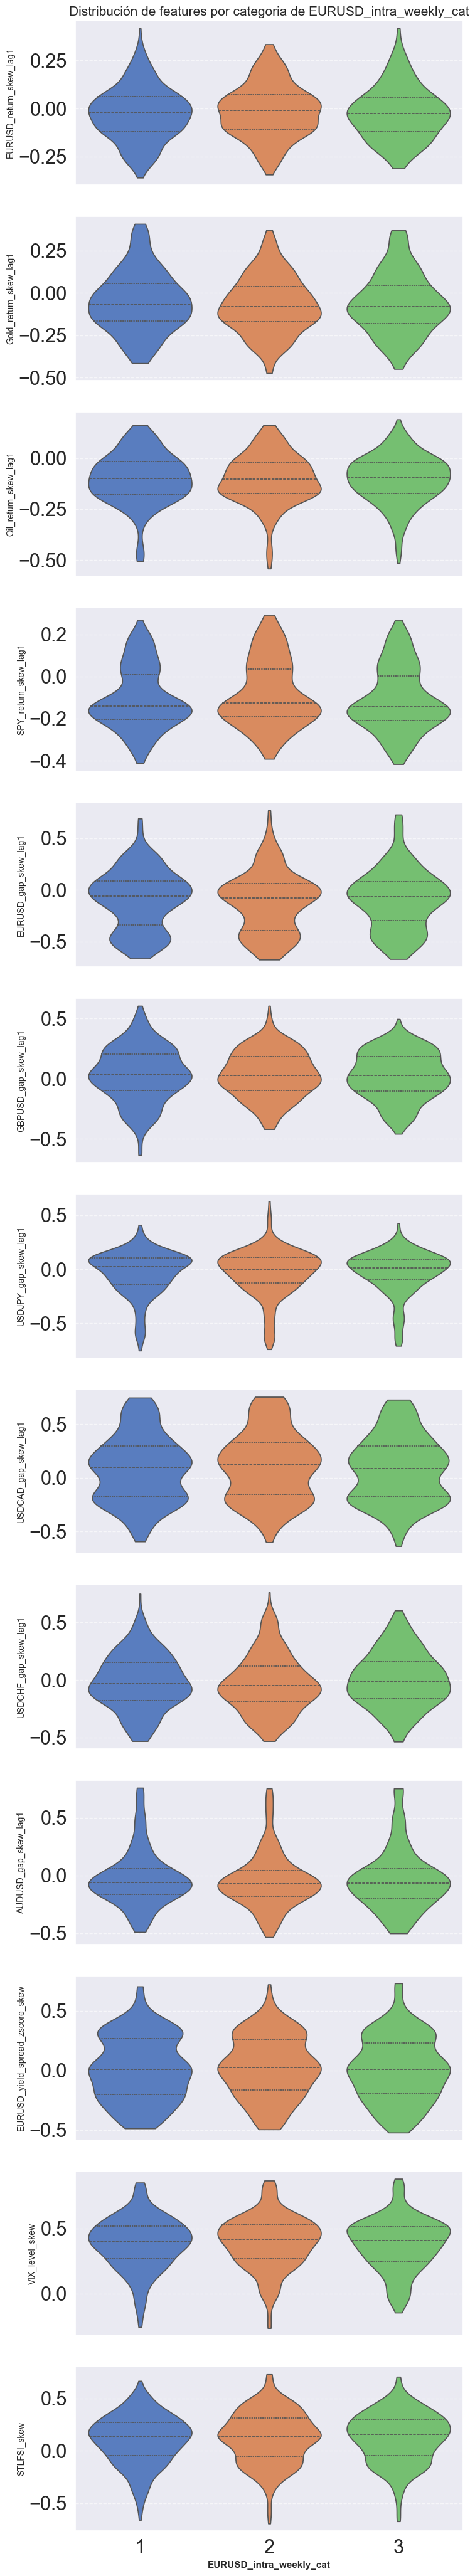

In [22]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

# Filtrar predictores
cadena = "_skew"
columnas = encontrar_columnas(columnas_target=numeric_cols, cadena=cadena)

pintar_violin_plots(
    df=df_train,
    numeric_cols=columnas,
    target_col=target_col
)